# Automated Waste Classification Using CNN and Transfer Learning

## 1. Project Setup

This project aims to classify waste images into six categories
using Convolutional Neural Networks and Transfer Learning.

Dataset: TrashNet

Download dataset

In [3]:
!mkdir -p data

!wget -O dataset-resized.zip \
https://github.com/garythung/trashnet/raw/master/data/dataset-resized.zip

--2026-11-20 05:36:58--  https://github.com/garythung/trashnet/raw/master/data/dataset-resized.zip
Resolving github.com (github.com)... 140.82.112.4
Connecting to github.com (github.com)|140.82.112.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/garythung/trashnet/master/data/dataset-resized.zip [following]
--2026-11-20 05:36:58--  https://raw.githubusercontent.com/garythung/trashnet/master/data/dataset-resized.zip
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.110.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 42834870 (41M) [application/zip]
Saving to: ‘dataset-resized.zip’

dataset-resized.zip 100%[===================>]  40.85M   228MB/s    in 0.2s    

2026-11-20 05:36:59 (228 MB/s) - ‘dataset-resized.zip’ saved [42834870/42834870]



Extract dataset

In [4]:
!unzip -q dataset-resized.zip -d data

In [5]:
import os

DATASET_PATH = "/content/data/dataset-resized"

print(os.listdir(DATASET_PATH))

['trash', 'cardboard', 'plastic', '.DS_Store', 'glass', 'metal', 'paper']


Import Libraries

In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
)

print("Tensorflow version: ", tf.__version__)
print("GPU available: ", tf.config.list_physical_devices('GPU'))

Tensorflow version:  2.21.0
GPU available:  [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# 2.Exploratory Data Analysis (EDA)

Count images

In [7]:
import os

DATASET_PATH = "/content/data/dataset-resized"

class_names = [
    folder for folder in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, folder))
    and not folder.startswith(".")
]

class_names.sort()

for class_name in class_names:

    folder_path = os.path.join(DATASET_PATH, class_name)

    image_count = len([
        file for file in os.listdir(folder_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    print(class_name, ":", image_count)

cardboard : 403
glass : 501
metal : 410
paper : 594
plastic : 482
trash : 137


Create a dataset summary table

In [8]:
import pandas as pd

class_counts = {}

for class_name in class_names:

    folder_path = os.path.join(DATASET_PATH, class_name)

    image_count = len([
        file for file in os.listdir(folder_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    class_counts[class_name] = image_count

df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Number of Images"]
)

print(df)

print("\nTotal Images:", df["Number of Images"].sum())

       Class  Number of Images
0  cardboard               403
1      glass               501
2      metal               410
3      paper               594
4    plastic               482
5      trash               137

Total Images: 2527


Visualize class distribution

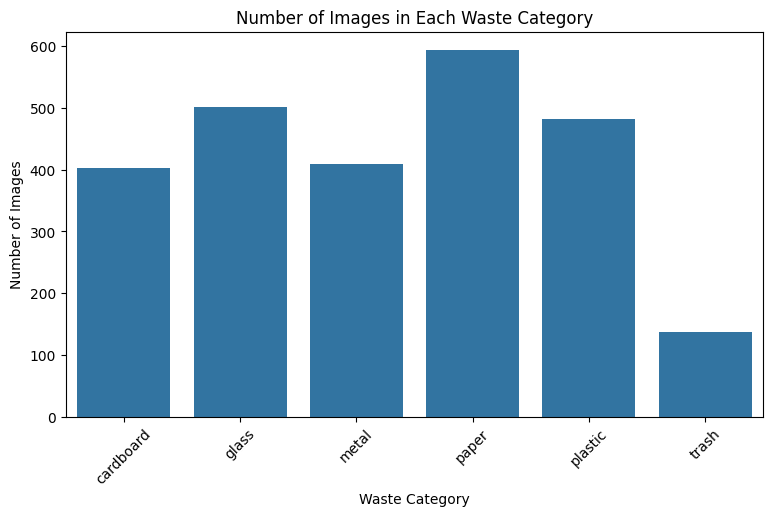

In [9]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=df,
    x="Class",
    y="Number of Images"
)

plt.title("Number of Images in Each Waste Category")
plt.xlabel("Waste Category")
plt.ylabel("Number of Images")

plt.xticks(rotation=45)

plt.show()

Display sample images

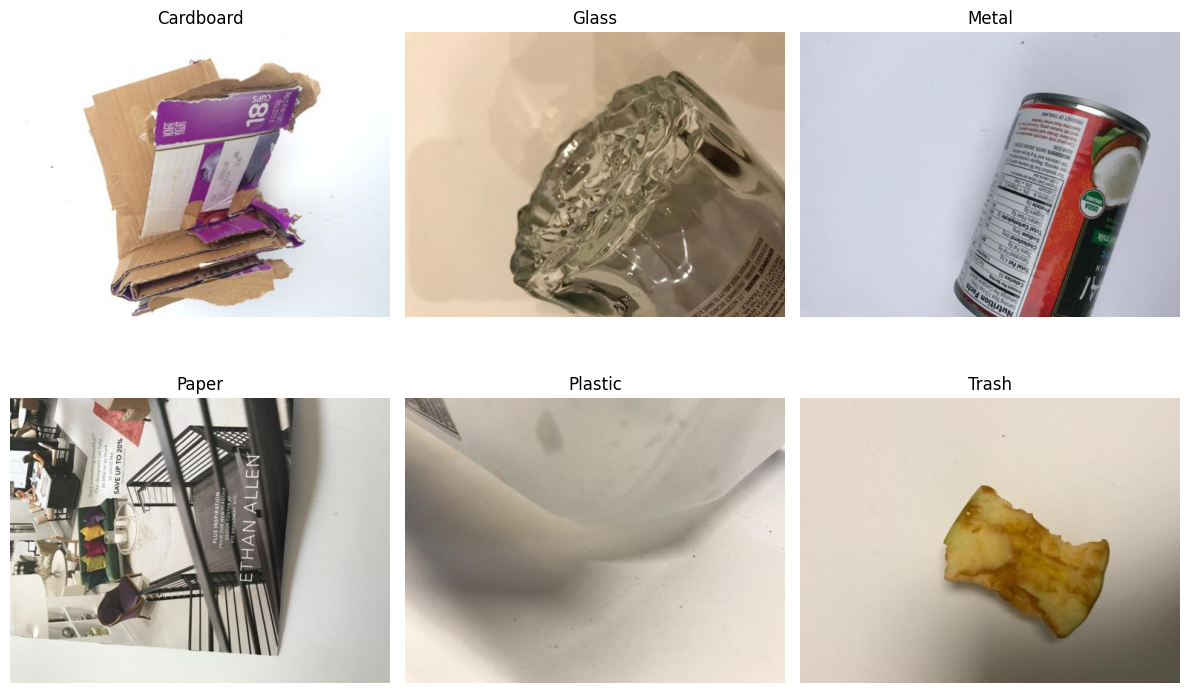

In [10]:
import random
from tensorflow.keras.utils import load_img

plt.figure(figsize=(12, 8))

for i, class_name in enumerate(class_names):

    folder_path = os.path.join(DATASET_PATH, class_name)

    image_files = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    random_image = random.choice(image_files)

    image_path = os.path.join(folder_path, random_image)

    img = load_img(image_path)

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(class_name.capitalize())
    plt.axis("off")

plt.tight_layout()
plt.show()

Check image dimaensions

In [11]:
from PIL import Image

image_dimensions = []

for class_name in class_names:

    folder_path = os.path.join(DATASET_PATH, class_name)

    for filename in os.listdir(folder_path):

        if filename.lower().endswith((".jpg", ".jpeg", ".png")):

            image_path = os.path.join(folder_path, filename)

            with Image.open(image_path) as img:
                image_dimensions.append(img.size)

dimension_df = pd.DataFrame(
    image_dimensions,
    columns=["Width", "Height"]
)

print(dimension_df.describe())

print("\nUnique image dimensions:",
      dimension_df.drop_duplicates().shape[0])

        Width  Height
count  2527.0  2527.0
mean    512.0   384.0
std       0.0     0.0
min     512.0   384.0
25%     512.0   384.0
50%     512.0   384.0
75%     512.0   384.0
max     512.0   384.0

Unique image dimensions: 1


### Exploratory Data Analysis – Findings

The TrashNet dataset contains 2,527 images distributed across six waste categories: cardboard, glass, metal, paper, plastic, and trash.

The paper category has the highest number of images (594), representing approximately 23.51% of the dataset. The trash category has the lowest number of images (137), representing approximately 5.42%.

The analysis identified class imbalance within the dataset, which may influence the classification performance of the models, particularly for underrepresented categories.

All 2,527 images have consistent dimensions of 512 × 384 pixels. No variations in image dimensions were identified during the inspection.

Visual inspection confirmed that the sample images from all six categories were clear and readable.

These findings will guide the subsequent preprocessing, data augmentation, model training, and evaluation stages.

# Data Preprocessing

Creating image paths and labels

In [12]:
import os
import pandas as pd

image_paths = []
image_labels = []

for class_name in class_names:

    folder_path = os.path.join(DATASET_PATH, class_name)

    for filename in os.listdir(folder_path):

        if filename.lower().endswith((".jpg", ".jpeg", ".png")):

            image_path = os.path.join(folder_path, filename)

            image_paths.append(image_path)
            image_labels.append(class_name)

data_df = pd.DataFrame({
    "image_path": image_paths,
    "label": image_labels
})

print(data_df.head())
print("\nTotal images:", len(data_df))

                                          image_path      label
0  /content/data/dataset-resized/cardboard/cardbo...  cardboard
1  /content/data/dataset-resized/cardboard/cardbo...  cardboard
2  /content/data/dataset-resized/cardboard/cardbo...  cardboard
3  /content/data/dataset-resized/cardboard/cardbo...  cardboard
4  /content/data/dataset-resized/cardboard/cardbo...  cardboard

Total images: 2527


Perform stratified splitting

In [13]:
#split 70% for training and 30% temporary

train_df, temp_df = train_test_split(
    data_df,
    test_size = 0.30,
    random_state=42,
    stratify=data_df["label"]
)

#divide the temporary data equally
val_df, test_df = train_test_split(
    temp_df,
    test_size = 0.50,
    random_state = 42,
    stratify = temp_df["label"]
)

print("Training images: ", len(train_df))
print("Validation images: ", len(val_df))
print("Testiing images: ", len(test_df))

Training images:  1768
Validation images:  379
Testiing images:  380


Class distribution

In [14]:
split_distribution = pd.DataFrame({
    "Training": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Testing": test_df["label"].value_counts()
})

print(split_distribution)

           Training  Validation  Testing
label                                   
cardboard       282          61       60
glass           350          75       76
metal           287          61       62
paper           416          89       89
plastic         337          72       73
trash            96          21       20


Encode class labels

In [15]:
# Create a mapping between class names and numbers

label_to_index = {
    name: index for index, name in enumerate(class_names)
}

print(label_to_index)

{'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}


Image loading function

In [16]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def load_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize_with_pad(
        image,
        IMG_SIZE[0],
        IMG_SIZE[1]
    )

    return image, label

Create tensorflow datasets

In [17]:
AUTOTUNE = tf.data.AUTOTUNE

def create_dataset(df):

    paths = df["image_path"].values

    labels = df["label"].map(label_to_index).values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_dataset = create_dataset(train_df)
val_dataset = create_dataset(val_df)
test_dataset = create_dataset(test_df)

In [18]:
for images, labels in train_dataset.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 255.0


**Building a CNN from Scratch**

Calculate class weights

In [19]:
from sklearn.utils.class_weight import compute_class_weight

y_train = train_df["label"].map(label_to_index).values

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(class_names)),
    y=y_train
)

class_weights = {
    i: weight
    for i, weight in enumerate(class_weights_array)
}

print("Class weights:")

for i, weight in class_weights.items():
    print(class_names[i], ":", round(weight, 3))

Class weights:
cardboard : 1.045
glass : 0.842
metal : 1.027
paper : 0.708
plastic : 0.874
trash : 3.069


Data augmentation

In [20]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1)
])

Build the CNN model

In [21]:
model_cnn = keras.Sequential([

    layers.Input(shape=(224, 224, 3)),

    # Data augmentation
    data_augmentation,

    # Normalization
    layers.Rescaling(1./255),

    # Convolution Block 1
    layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    layers.Conv2D(
        128, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    # Feature aggregation
    layers.GlobalAveragePooling2D(),

    # Classification layers
    layers.Dense(128, activation="relu"),

    layers.Dropout(0.4),

    # Six output classes
    layers.Dense(6, activation="softmax")

])

model_cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,534 (431.77 KB)

 Trainable params: 110,534 (431.77 KB)

 Non-trainable params: 0 (0.00 B)

Compile the model

In [22]:
model_cnn.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

Define callbacks

In [23]:
callbacks = [

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.00001
    )

]

Train the model

In [24]:
history_cnn = model_cnn.fit(

    train_dataset,

    validation_data=val_dataset,

    epochs=30,

    class_weight=class_weights,

    callbacks=callbacks

)

Epoch 1/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 13s 85ms/step - accuracy: 0.2438 - loss: 1.7628 - val_accuracy: 0.3087 - val_loss: 1.6116 - learning_rate: 0.0010
Epoch 2/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step - accuracy: 0.3167 - loss: 1.6051 - val_accuracy: 0.3404 - val_loss: 1.5447 - learning_rate: 0.0010
Epoch 3/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - accuracy: 0.3512 - loss: 1.5418 - val_accuracy: 0.3166 - val_loss: 1.5767 - learning_rate: 0.0010
Epoch 4/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 81ms/step - accuracy: 0.3490 - loss: 1.5118 - val_accuracy: 0.3483 - val_loss: 1.4727 - learning_rate: 0.0010
Epoch 5/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - accuracy: 0.3546 - loss: 1.5025 - val_accuracy: 0.4090 - val_loss: 1.4665 - learning_rate: 0.0010
Epoch 6/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step - accuracy: 0.3891 - loss: 1.4540 - val_accuracy: 0.4142 - val_loss: 1.4109 - learning_rate: 0.0010
Epoch 7/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 79ms/step - accuracy: 0.4010 - loss: 1.4365 - val_ac

Visualizing Training performance

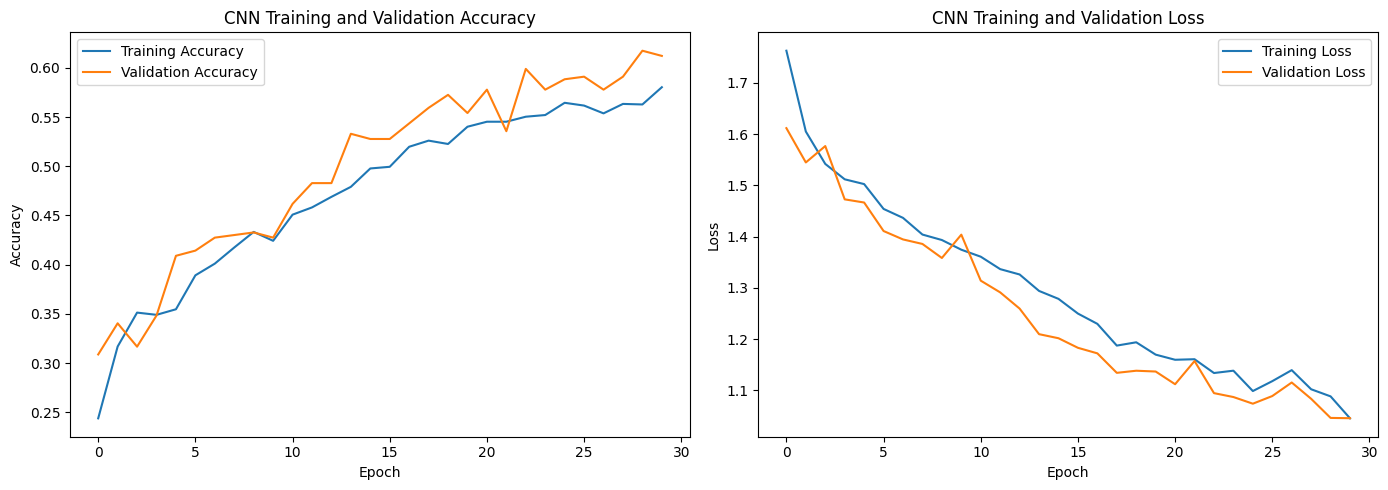

In [25]:
plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    history_cnn.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_cnn.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()


# Loss
plt.subplot(1, 2, 2)

plt.plot(
    history_cnn.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_cnn.history["val_loss"],
    label="Validation Loss"
)

plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [26]:
os.makedirs("/content/models", exist_ok=True)

model_cnn.save("/content/models/custom_cnn.keras")

print("CNN model saved successfully!")

CNN model saved successfully!


In [27]:
callbacks_more = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=0.00001
    )
]

history_cnn_more = model_cnn.fit(
    train_dataset,
    validation_data=val_dataset,
    initial_epoch=30,
    epochs=60,
    class_weight=class_weights,
    callbacks=callbacks_more
)

Epoch 31/60
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step - accuracy: 0.5871 - loss: 1.0454 - val_accuracy: 0.6095 - val_loss: 1.0326 - learning_rate: 5.0000e-04
Epoch 32/60
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step - accuracy: 0.5820 - loss: 1.0556 - val_accuracy: 0.6148 - val_loss: 1.0289 - learning_rate: 5.0000e-04
Epoch 33/60
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 71ms/step - accuracy: 0.5973 - loss: 1.0338 - val_accuracy: 0.6201 - val_loss: 1.0440 - learning_rate: 5.0000e-04
Epoch 34/60
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 68ms/step - accuracy: 0.6035 - loss: 1.0026 - val_accuracy: 0.6174 - val_loss: 1.0059 - learning_rate: 5.0000e-04
Epoch 35/60
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 65ms/step - accuracy: 0.5933 - loss: 1.0084 - val_accuracy: 0.6306 - val_loss: 1.0111 - learning_rate: 5.0000e-04
Epoch 36/60
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 81ms/step - accuracy: 0.5877 - loss: 1.0346 - val_accuracy: 0.6201 - val_loss: 0.9936 - learning_rate: 5.0000e-04
Epoch 37/60
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 66ms/step - accuracy: 

Plot the complete training history

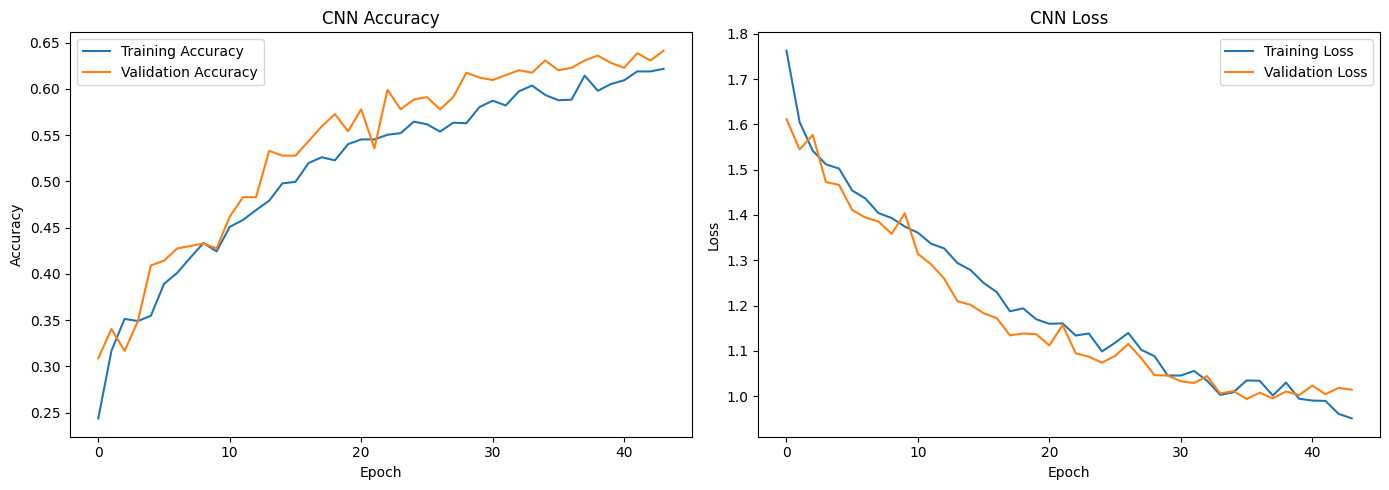

In [28]:
accuracy = (
    history_cnn.history["accuracy"] +
    history_cnn_more.history["accuracy"]
)

val_accuracy = (
    history_cnn.history["val_accuracy"] +
    history_cnn_more.history["val_accuracy"]
)

loss = (
    history_cnn.history["loss"] +
    history_cnn_more.history["loss"]
)

val_loss = (
    history_cnn.history["val_loss"] +
    history_cnn_more.history["val_loss"]
)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(accuracy, label="Training Accuracy")
plt.plot(val_accuracy, label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [29]:
model_cnn.save("/content/models/custom_cnn.keras")

print("Updated CNN model saved successfully!")

Updated CNN model saved successfully!


# Evaluate the CNN using test data

In [30]:
test_loss, test_accuracy = model_cnn.evaluate(test_dataset)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step - accuracy: 0.6395 - loss: 0.9852
Test Accuracy: 63.95 %
Test Loss: 0.9852


Classification report and confusion matrix

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step
              precision    recall  f1-score   support

   cardboard       0.77      0.80      0.79        60
       glass       0.63      0.43      0.52        76
       metal       0.69      0.65      0.67        62
       paper       0.63      0.89      0.74        89
     plastic       0.71      0.44      0.54        73
       trash       0.29      0.55      0.38        20

    accuracy                           0.64       380
   macro avg       0.62      0.63      0.60       380
weighted avg       0.66      0.64      0.63       380



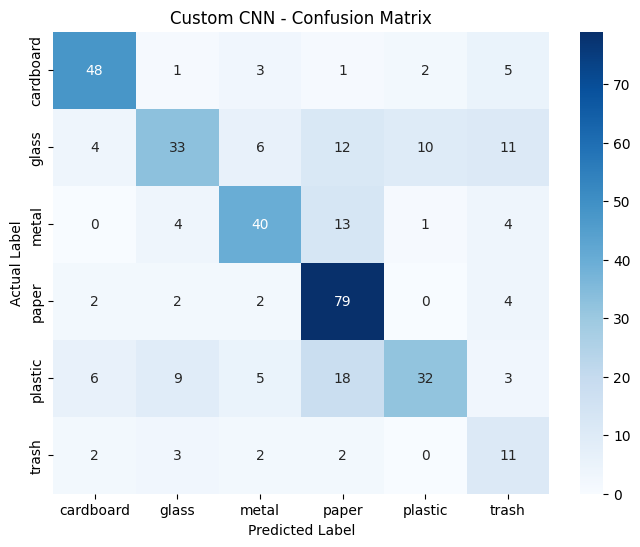

In [31]:
from sklearn.metrics import classification_report, confusion_matrix

# Actual labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_dataset
])

# Predicted probabilities
y_prob = model_cnn.predict(test_dataset)

# Predicted classes
y_pred = np.argmax(y_prob, axis=1)

# Classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Custom CNN - Confusion Matrix")
plt.show()

Custom CNN Evaluation Findings
- The custom CNN achieved 65% accuracy on the independent test dataset.
- Paper achieved the highest F1-score of 0.77, followed by cardboard at 0.75.
- Trash had the lowest F1-score of 0.46, indicating difficulty distinguishing this category from other waste types.
- Metal and plastic also showed relatively low recall.
- The macro F1-score was 0.63, while the weighted F1-score was 0.65.
- These results indicate that the custom CNN provides a baseline model, with opportunities for improvement through transfer learning.

# MobileNetV2 – Transfer Learning

Custom CNN: Learns image features from scratch using your 1,768 training images.



MobileNetV2: Starts with features learned from a much larger ImageNet dataset and adapts them to your six waste categories.

In [32]:
base_model = keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

print("MobileNetV2 loaded successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 loaded successfully!


Freeze the pretrained layers

In [33]:
base_model.trainable = False

print("Total layers:", len(base_model.layers))
print("Trainable:", base_model.trainable)

Total layers: 154
Trainable: False


Build the MobileNetV2 classification model

In [34]:
model_mobilenet = keras.Sequential([
    layers.Input(shape=(224, 224, 3)),

    data_augmentation,

    layers.Rescaling(1./127.5, offset=-1),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.3),

    layers.Dense(6, activation="softmax")
])

model_mobilenet.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Compile the model

In [35]:
model_mobilenet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

In [36]:
callbacks_mobilenet = [

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.00001
    )
]

Train MobileNetV2 – Stage 1

In [37]:
history_mobilenet = model_mobilenet.fit(
    train_dataset,

    validation_data=val_dataset,

    epochs=20,

    class_weight=class_weights,

    callbacks=callbacks_mobilenet
)

Epoch 1/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 17s 152ms/step - accuracy: 0.4615 - loss: 1.4069 - val_accuracy: 0.7071 - val_loss: 0.7940 - learning_rate: 0.0010
Epoch 2/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 75ms/step - accuracy: 0.6606 - loss: 0.9313 - val_accuracy: 0.7678 - val_loss: 0.6971 - learning_rate: 0.0010
Epoch 3/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 89ms/step - accuracy: 0.7144 - loss: 0.7926 - val_accuracy: 0.7731 - val_loss: 0.6359 - learning_rate: 0.0010
Epoch 4/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - accuracy: 0.7172 - loss: 0.7660 - val_accuracy: 0.7704 - val_loss: 0.6174 - learning_rate: 0.0010
Epoch 5/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - accuracy: 0.7489 - loss: 0.6845 - val_accuracy: 0.7784 - val_loss: 0.5968 - learning_rate: 0.0010
Epoch 6/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 88ms/step - accuracy: 0.7607 - loss: 0.6618 - val_accuracy: 0.8127 - val_loss: 0.5385 - learning_rate: 0.0010
Epoch 7/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - accuracy: 0.7602 - loss: 0.6116 - val_a

Plot training and validation graphs

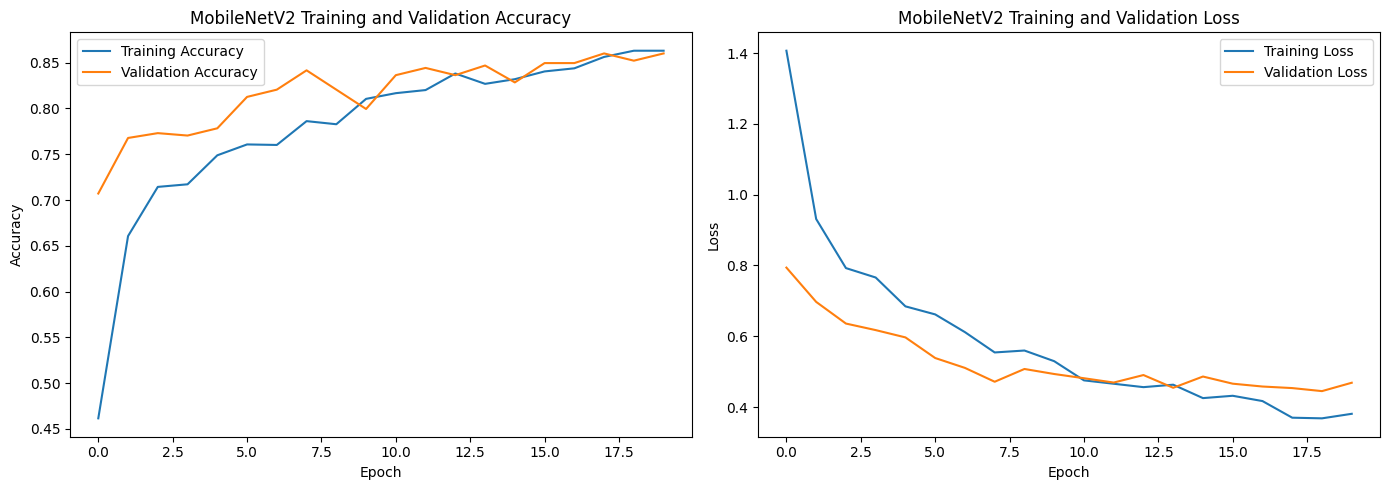

In [38]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(
    history_mobilenet.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_mobilenet.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("MobileNetV2 Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()


plt.subplot(1, 2, 2)

plt.plot(
    history_mobilenet.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_mobilenet.history["val_loss"],
    label="Validation Loss"
)

plt.title("MobileNetV2 Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [39]:
model_mobilenet.save("/content/models/mobilenet_stage1.keras")

print("MobileNetV2 Stage 1 model saved successfully!")

MobileNetV2 Stage 1 model saved successfully!


**Fine-tuning MobileNetV2**

In [40]:
# Allow the base model to be trainable
base_model.trainable = True

# Freeze all layers first
for layer in base_model.layers:
    layer.trainable = False

# Unfreeze only the last 30 layers
for layer in base_model.layers[-30:]:
    if not isinstance(layer, layers.BatchNormalization):
        layer.trainable = True

print("Total MobileNetV2 layers:", len(base_model.layers))

print(
    "Trainable MobileNetV2 layers:",
    sum(layer.trainable for layer in base_model.layers)
)

Total MobileNetV2 layers: 154
Trainable MobileNetV2 layers: 19


Compile the model

In [41]:
model_mobilenet.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [42]:
callbacks_finetune = [

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.000001
    )
]

Train the fine-tuned model

In [43]:
history_finetune = model_mobilenet.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=15,
    class_weight=class_weights,
    callbacks=callbacks_finetune
)

Epoch 1/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 15s 114ms/step - accuracy: 0.8467 - loss: 0.3895 - val_accuracy: 0.8549 - val_loss: 0.4580 - learning_rate: 1.0000e-05
Epoch 2/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 95ms/step - accuracy: 0.8620 - loss: 0.3660 - val_accuracy: 0.8443 - val_loss: 0.4580 - learning_rate: 1.0000e-05
Epoch 3/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 90ms/step - accuracy: 0.8626 - loss: 0.3529 - val_accuracy: 0.8575 - val_loss: 0.4554 - learning_rate: 1.0000e-05
Epoch 4/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 87ms/step - accuracy: 0.8727 - loss: 0.3347 - val_accuracy: 0.8602 - val_loss: 0.4520 - learning_rate: 1.0000e-05
Epoch 5/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 95ms/step - accuracy: 0.8801 - loss: 0.3226 - val_accuracy: 0.8417 - val_loss: 0.4569 - learning_rate: 1.0000e-05
Epoch 6/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 86ms/step - accuracy: 0.8790 - loss: 0.3038 - val_accuracy: 0.8628 - val_loss: 0.4519 - learning_rate: 1.0000e-05
Epoch 7/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 100ms/step - accuracy: 0.89

Plot fine-tuning results

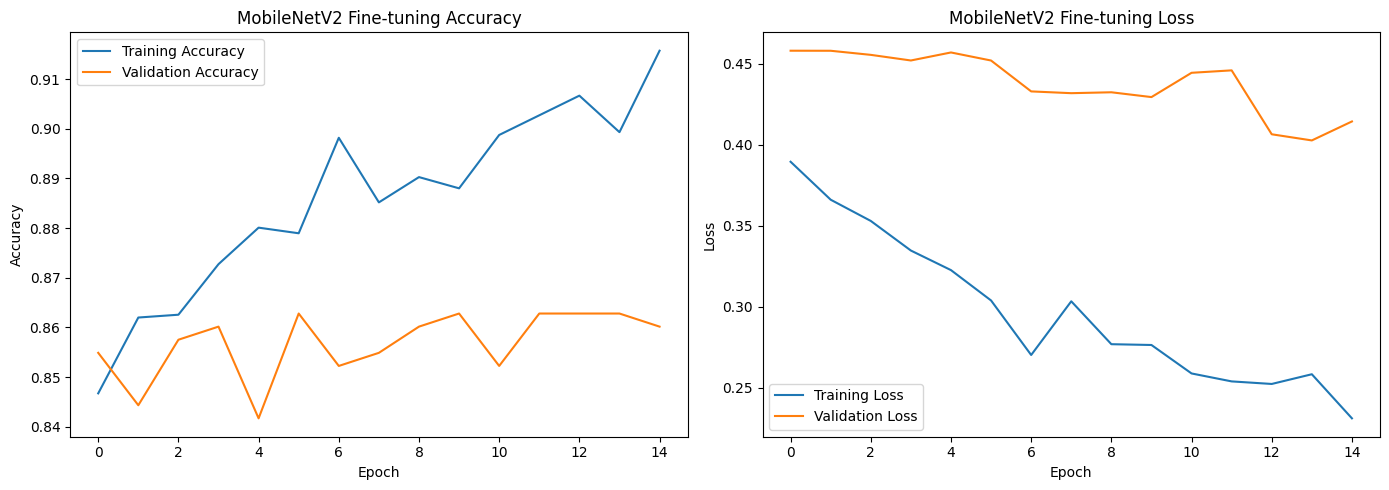

In [44]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(
    history_finetune.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_finetune.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("MobileNetV2 Fine-tuning Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()


plt.subplot(1, 2, 2)

plt.plot(
    history_finetune.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_finetune.history["val_loss"],
    label="Validation Loss"
)

plt.title("MobileNetV2 Fine-tuning Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [45]:
model_mobilenet.save(
    "/content/models/mobilenet_finetuned.keras"
)

print("Fine-tuned MobileNetV2 saved successfully!")

Fine-tuned MobileNetV2 saved successfully!


**MobileNetV2 test evaluation**

In [46]:
test_loss_mobilenet, test_accuracy_mobilenet = model_mobilenet.evaluate(
    test_dataset
)

print("MobileNetV2 Test Accuracy:",
      round(test_accuracy_mobilenet * 100, 2), "%")

print("MobileNetV2 Test Loss:",
      round(test_loss_mobilenet, 4))

12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 170ms/step - accuracy: 0.8105 - loss: 0.5539
MobileNetV2 Test Accuracy: 81.05 %
MobileNetV2 Test Loss: 0.5539


Generate classifiacation report

In [47]:
from sklearn.metrics import classification_report, confusion_matrix

# Get actual labels
y_true_mobilenet = np.concatenate([
    labels.numpy()
    for images, labels in test_dataset
])

# Predict probabilities
y_prob_mobilenet = model_mobilenet.predict(test_dataset)

# Convert probabilities into predicted class labels
y_pred_mobilenet = np.argmax(y_prob_mobilenet, axis=1)

# Generate classification report
print(classification_report(
    y_true_mobilenet,
    y_pred_mobilenet,
    target_names=class_names
))

12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 248ms/step
              precision    recall  f1-score   support

   cardboard       0.89      0.98      0.94        60
       glass       0.74      0.72      0.73        76
       metal       0.78      0.92      0.84        62
       paper       0.96      0.83      0.89        89
     plastic       0.77      0.66      0.71        73
       trash       0.54      0.75      0.62        20

    accuracy                           0.81       380
   macro avg       0.78      0.81      0.79       380
weighted avg       0.82      0.81      0.81       380



Generate the confusion matrix

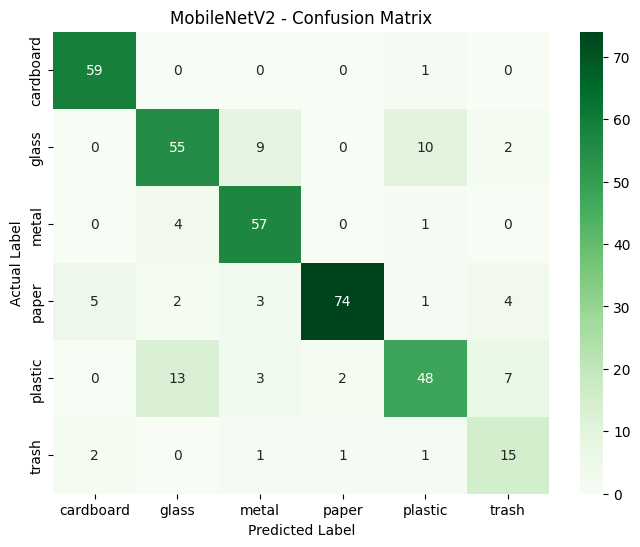

In [48]:
cm_mobilenet = confusion_matrix(
    y_true_mobilenet,
    y_pred_mobilenet
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_mobilenet,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("MobileNetV2 - Confusion Matrix")

plt.show()

**Compare Custom CNN and MobileNetV2**

In [49]:
comparison_df = pd.DataFrame({
    "Model": ["Custom CNN", "MobileNetV2"],
    "Test Accuracy": [
        test_accuracy,
        test_accuracy_mobilenet
    ],
    "Test Loss": [
        test_loss,
        test_loss_mobilenet
    ]
})

comparison_df["Test Accuracy"] = (
    comparison_df["Test Accuracy"] * 100
)

print(comparison_df)

         Model  Test Accuracy  Test Loss
0   Custom CNN      63.947368   0.985195
1  MobileNetV2      81.052631   0.553937


Visualize the comparison

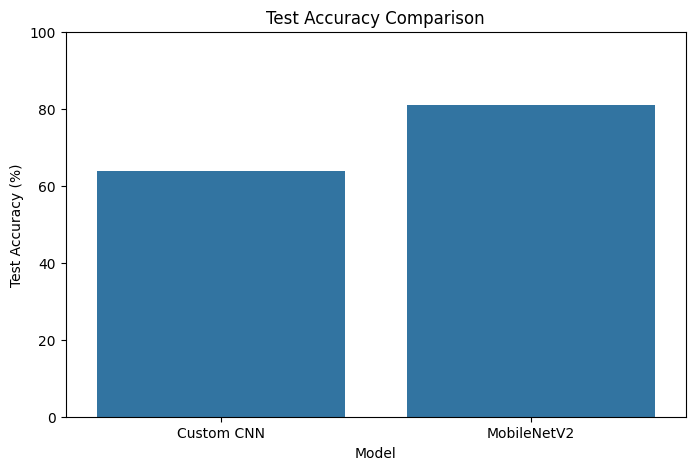

In [50]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Test Accuracy"
)

plt.title("Test Accuracy Comparison")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)

plt.show()

### Model Comparison and Evaluation Findings

Two deep learning models were developed and evaluated for automated waste classification: a Custom Convolutional Neural Network (CNN) and MobileNetV2 using transfer learning.

The Custom CNN achieved a test accuracy of **63.95%**, with a test loss of 0.9852. In comparison, MobileNetV2 achieved a significantly higher test accuracy of **81.05%**, with a lower test loss of 0.5539.

MobileNetV2 achieved a weighted F1-score of 0.81 and a macro F1-score of 0.79. It performed particularly well in classifying cardboard (F1-score: 0.94), paper (0.89), and metal (0.84).

However, trash (0.62) and plastic (0.71) remained comparatively challenging categories.

Overall, MobileNetV2 outperformed the Custom CNN in test accuracy and F1-score across all six waste categories. These findings demonstrate the benefits of transfer learning for this waste classification task.

In [51]:
model_mobilenet.save(
    "/content/models/final_mobilenetv2.keras"
)

print("Final MobileNetV2 model saved successfully!")

Final MobileNetV2 model saved successfully!


# **Predicting new waste images**

In [52]:
model = keras.models.load_model(
    "/content/models/final_mobilenetv2.keras"
)

print("Final model loaded successfully!")

Final model loaded successfully!


Prediction function

In [53]:
def predict_waste(image_path):

    # Read the image
    image = tf.io.read_file(image_path)

    # Decode image into RGB format
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    # Resize while preserving aspect ratio
    image = tf.image.resize_with_pad(
        image,
        224,
        224
    )

    # Add batch dimension
    image = tf.expand_dims(image, axis=0)

    # Predict probabilities
    predictions = model.predict(image, verbose=0)[0]

    # Find the class with the highest probability
    predicted_index = np.argmax(predictions)

    predicted_class = class_names[predicted_index]

    confidence = predictions[predicted_index] * 100

    print("Predicted Category:", predicted_class)
    print("Confidence:", round(float(confidence), 2), "%")

    return predictions

Uplaod a new waste image

In [54]:
from google.colab import files

uploaded = files.upload()

image_path = next(iter(uploaded.keys()))

print("Uploaded image:", image_path)

Saving images.jpeg to images.jpeg
Uploaded image: images.jpeg


Display probabilities for all six categories

In [56]:
from PIL import Image

Predicted Category: plastic
Confidence: 97.46 %


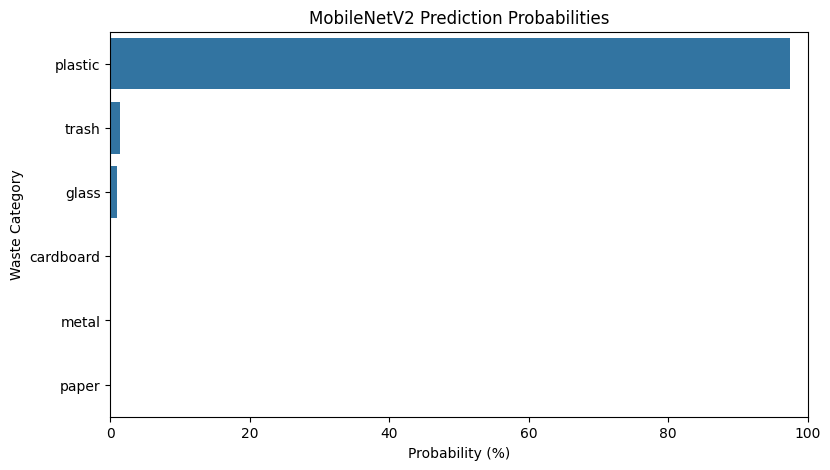

In [58]:
# Call predict_waste first to obtain the predictions vector
predictions = predict_waste(image_path)

probability_df = pd.DataFrame({
    "Category": class_names,
    "Probability": predictions * 100
})

probability_df = probability_df.sort_values(
    by="Probability",
    ascending=False
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=probability_df,
    x="Probability",
    y="Category"
)

plt.title("MobileNetV2 Prediction Probabilities")
plt.xlabel("Probability (%)")
plt.ylabel("Waste Category")
plt.xlim(0, 100)

plt.show()

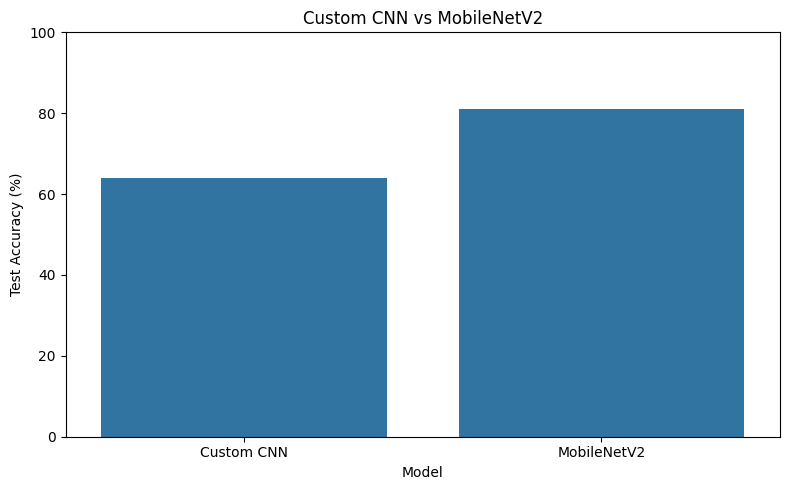

In [59]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Test Accuracy"
)

plt.title("Custom CNN vs MobileNetV2")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)

plt.tight_layout()

plt.savefig(
    "/content/models/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [60]:
comparison_df.to_csv(
    "/content/models/model_comparison.csv",
    index=False
)

print("Model comparison results saved!")

Model comparison results saved!


In [61]:
import json

with open(
    "/content/models/class_names.json",
    "w"
) as file:

    json.dump(class_names, file)

print("Class names saved successfully!")

Class names saved successfully!
